# 02 Smoke test (stage G3)

Before the whole window is processed, the frozen Haenam detection chain runs on four test days:
- **2021-08-27 and 08-28** (DOY 239-240): five of the KMA-listed 2021 events, including the ML 2.2;
- **2026-01-01** (DOY 1): two KMA events of 2026;
- **2013-07-19** (DOY 200): a sparse-network day (10 stations within 100 km).

The chain is PhaseNet+ (frozen Haenam weights) → PyOcto association → HYPOINVERSE (Kim & Kim 1983 model), with the one-sensor station table of this project.

The test passes when:
1. picks come from (nearly) every station that recorded;
2. every KMA event on these days is located within 12 s of its KMA origin time;
3. the ML 2.2 locates within about 1 km of the earlier precise relocation (`gwangyang_pnplus`), at 12-16 km depth;
4. PhaseNet+ agrees with the manual picks of the earlier study: median |difference| ≤ 0.1 s for P and ≤ 0.2 s for S.

In [1]:
import os, sys, glob
import numpy as np, pandas as pd
ROOT = '/home/msseo/works/73.Gwangyang_sequence'
sys.path.insert(0, f'{ROOT}/detection/pipeline'); sys.path.insert(0, f'{ROOT}/registry')
import config, plotstyle  # noqa: F401
from sumio import read_sum
import matplotlib.pyplot as plt
import obspy
from obspy import UTCDateTime
pd.set_option('display.width', 220)
DAYS = [(2021, 239), (2021, 240), (2026, 1), (2013, 200)]
st = pd.read_csv(config.STATIONS_CSV)
rows = []
for y, d in DAYS:
    linked = {f'{r.Network}.{r.Code}' for r in st.itertuples() if os.path.exists(os.path.join(config.CONTINUOUS, r.Network, r.Code, f'{r.Sensor}Z.D', f'{r.Network}.{r.Code}..{r.Sensor}Z.D.{y}.{d:03d}'))}
    pk = pd.read_csv(os.path.join(config.picks_dir('phasenet_plus', y), f'picks_{y}.{d:03d}.csv'))
    rows.append(dict(day=f'{y}-{d:03d}', stations_linked=len(linked), stations_with_picks=pk.station.nunique(), P=int((pk.phase == 'P').sum()), S=int((pk.phase == 'S').sum()),
                     linked_without_picks=', '.join(sorted(linked - set(pk.station)))))
picks_tab = pd.DataFrame(rows); display(picks_tab)

,day,stations_linked,stations_with_picks,P,S,linked_without_picks
0,2021-239,53,60,3993,5764,
1,2021-240,54,61,4076,5843,
2,2026-001,77,76,5595,7305,KS.EURB
3,2013-200,10,10,391,497,


In [2]:
sums = {y: read_sum(os.path.join(config.velmodel_dir('phasenet_plus', 'kim1983'), f'{config.REGION_NAME}{y}.sum')) for y in (2013, 2021, 2026)}
loc = pd.concat([s.assign(year=y) for y, s in sums.items()], ignore_index=True)
loc = loc[loc.time.notna()]
loc['dist_km'] = 111.2 * np.hypot(loc.lat - config.HAENAM_EPICENTER[0], (loc.lon - config.HAENAM_EPICENTER[1]) * np.cos(np.radians(config.HAENAM_EPICENTER[0])))
print('located events per test day:', loc.groupby(loc.time.dt.strftime('%Y-%j')).size().to_dict())
ev = pd.read_csv(f'{ROOT}/registry/events.csv', parse_dates=['origin_time_utc'], dtype={'eid': str})
ev = ev[ev.origin_time_utc.dt.strftime('%Y-%j').isin([f'{y}-{d:03d}' for y, d in DAYS])].copy()
m = []
for r in ev.itertuples():
    dt = (loc.time - r.origin_time_utc).abs(); i = dt.idxmin()
    m.append(dict(kma_utc=r.origin_time_utc, ML=r.ML, dt_s=round(dt[i].total_seconds(), 2), lat=loc.lat[i], lon=loc.lon[i], depth=loc.depth[i], dist_from_centroid_km=round(loc.dist_km[i], 2),
                  num=loc.num[i], gap=loc.gap[i], rms=loc.rms[i], found=dt[i].total_seconds() <= 12))
kma_tab = pd.DataFrame(m); display(kma_tab)
KMA_OK = bool(kma_tab.found.all())
ref = pd.read_csv('/home/msseo/works/10.Earthquake_cycle_project/pipeline/runs/gwangyang_pnplus/2.HypoDD/02.dt.cc/final_locations.csv', dtype={'event_id': str})
ms = kma_tab[kma_tab.ML == kma_tab.ML.max()].iloc[0]
r0 = ref[ref.event_id.str.startswith('20210827220')].iloc[0]
ms_off = 111.2 * np.hypot(ms.lat - r0.latitude, (ms.lon - r0.longitude) * np.cos(np.radians(r0.latitude)))
print(f'ML {ms.ML} event: {ms.lat:.4f} N {ms.lon:.4f} E {ms.depth:.2f} km; earlier relocation {r0.latitude:.4f} N {r0.longitude:.4f} E {r0.depth_km:.2f} km -> epicentral offset {ms_off:.2f} km')
MS_OK = ms_off <= 1.0 and 12 <= ms.depth <= 16

located events per test day: {'2013-200': 1, '2021-238': 1, '2021-239': 17, '2021-240': 18, '2026-001': 9}


,kma_utc,ML,dt_s,lat,lon,depth,dist_from_centroid_km,num,gap,rms,found
0,2021-08-27 00:23:15,1.6,0.49,35.0014,127.7273,14.67,0.20,112,35,0.18,True
1,2021-08-27 22:03:22,2.2,1.19,35.0000,127.7272,15.22,0.13,112,35,0.17,True
2,2021-08-28 13:34:10,1.7,1.23,35.0003,127.7280,14.76,0.06,115,35,0.18,True
3,2021-08-28 13:39:22,1.1,0.79,35.0000,127.7285,14.95,0.01,71,39,0.22,True
4,2021-08-28 23:45:56,1.5,0.76,35.0007,127.7283,14.78,0.08,114,35,0.19,True
5,2026-01-01 02:49:47,1.4,0.55,34.9992,127.7276,14.96,0.13,82,40,0.22,True
6,2026-01-01 08:48:00,1.4,0.01,34.9998,127.7296,14.51,0.09,78,40,0.21,True


ML 2.2 event: 35.0000 N 127.7272 E 15.22 km; earlier relocation 34.9998 N 127.7285 E 13.93 km -> epicentral offset 0.12 km


PhaseNet+ minus manual picks: n = {'P': 231, 'S': 227} | median |difference| (s): {'P': 0.019, 'S': 0.02}


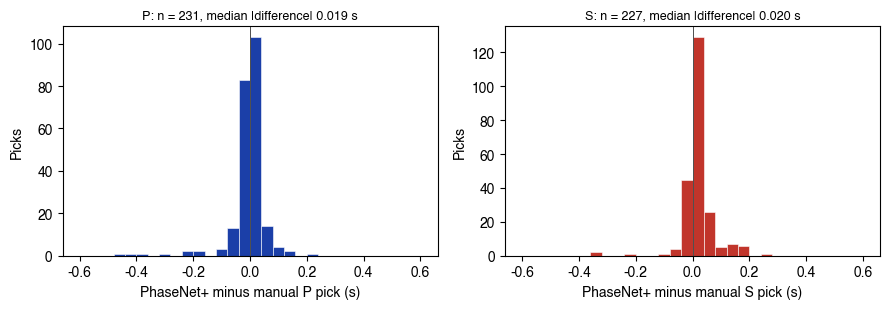

In [3]:
MAN = '/home/msseo/works/10.Earthquake_cycle_project/Gwangyang_sequence/manual_picks'
def sac_ref(h):
    return UTCDateTime(year=h.nzyear, julday=h.nzjday, hour=h.nzhour, minute=h.nzmin, second=h.nzsec, microsecond=int(h.nzmsec) * 1000)
cmp = []
for r in ev.itertuples():
    d = os.path.join(MAN, r.origin_time_utc.strftime('%Y%m%d%H%M%S'))
    y, j = r.origin_time_utc.year, r.origin_time_utc.dayofyear
    pk = pd.read_csv(os.path.join(config.picks_dir('phasenet_plus', y), f'picks_{y}.{j:03d}.csv'), parse_dates=['peak_time'])
    for f in sorted(glob.glob(f'{d}/*.sac')):
        tr = obspy.read(f, headonly=True)[0]; h = tr.stats.sac; ref_t = sac_ref(h)
        for key, ph, comps in (('a', 'P', 'Z'), ('t0', 'S', 'NE')):
            v = h.get(key, -12345.0)
            if v is None or v < -1e4 or tr.stats.channel[-1] not in comps:
                continue
            t_man = pd.Timestamp(str(ref_t + float(v))[:23])
            s = pk[(pk.station == f'{tr.stats.network}.{tr.stats.station}') & (pk.phase == ph)]
            if len(s):
                dd = (s.peak_time - t_man).dt.total_seconds(); k = dd.abs().idxmin()
                if abs(dd[k]) <= 1.5:
                    cmp.append(dict(event=r.origin_time_utc, station=tr.stats.station, phase=ph, diff_s=dd[k]))
cmp = pd.DataFrame(cmp).drop_duplicates(['event', 'station', 'phase'])
med = cmp.groupby('phase').diff_s.apply(lambda x: np.median(np.abs(x))).to_dict()
print('PhaseNet+ minus manual picks: n =', cmp.groupby('phase').size().to_dict(), '| median |difference| (s):', {k: round(v, 3) for k, v in med.items()})
PICK_OK = med.get('P', 9) <= 0.1 and med.get('S', 9) <= 0.2
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, ph in zip(ax, ('P', 'S')):
    x = cmp[cmp.phase == ph].diff_s
    a.hist(x, bins=np.arange(-0.6, 0.62, 0.04), color='#1b3fa8' if ph == 'P' else '#c1352b', edgecolor='white', lw=0.4)
    a.axvline(0, color='0.3', lw=0.7); a.set_xlabel(f'PhaseNet+ minus manual {ph} pick (s)'); a.set_ylabel('Picks')
    a.set_title(f'{ph}: n = {len(x)}, median |difference| {np.median(np.abs(x)):.3f} s', fontsize=9)
plt.tight_layout(); plt.show()

In [4]:
d13 = loc[loc.time.dt.strftime('%Y-%j') == '2013-200']
print(f'2013-07-19: {int(picks_tab.loc[picks_tab.day == "2013-200", "stations_linked"].iloc[0])} stations linked; {len(d13)} located events; '
      f'{int((d13.dist_km < 20).sum())} within 20 km of the cluster')
display(d13[['time', 'lat', 'lon', 'depth', 'num', 'gap', 'rms', 'erh', 'erz', 'dist_km']].round(3))

2013-07-19: 10 stations linked; 1 located events; 0 within 20 km of the cluster


,time,lat,lon,depth,num,gap,rms,erh,erz,dist_km
0,2013-07-19 03:14:39.750,35.473,127.309,3.92,6,333,0.04,1.4,2.6,65.043


## Comprehensive summary

In [5]:
STA_OK = bool((picks_tab.stations_with_picks >= 0.9 * picks_tab.stations_linked).all())
summ = pd.DataFrame([
    ('Stations with picks / stations linked', 'PASS' if STA_OK else 'CHECK', '; '.join(f'{r.day}: {r.stations_with_picks}/{r.stations_linked}' for r in picks_tab.itertuples())),
    ('KMA events located within 12 s', 'PASS' if KMA_OK else 'FAIL', f'{int(kma_tab.found.sum())} of {len(kma_tab)}; |dt| max {kma_tab.dt_s.max():.2f} s'),
    ('ML 2.2 vs earlier relocation', 'PASS' if MS_OK else 'FAIL', f'{ms_off:.2f} km epicentral, depth {ms.depth:.2f} km'),
    ('PhaseNet+ vs manual picks', 'PASS' if PICK_OK else 'FAIL', f"P {med.get('P', np.nan):.3f} s, S {med.get('S', np.nan):.3f} s median |difference| (n {len(cmp)})"),
    ('Sparse day 2013-07-19', 'info', f'{len(d13)} located events'),
], columns=['check', 'result', 'detail'])
display(summ)
print('SMOKE TEST:', 'PASS' if (KMA_OK and MS_OK and PICK_OK) else 'FAIL')
print('Take-homes:')
print('1. The frozen Haenam chain with the one-sensor station table finds the KMA-listed Gwangyang events on the test days and locates the ML 2.2 next to its earlier precise relocation.')
print('2. Automatic picks agree with the manual picks of the earlier study to a few hundredths of a second (P) and a few tens of milliseconds (S).')
print('3. On a 2013 day only 10 stations within 100 km record; detection then depends on GWYB and the KG broadbands.')

,check,result,detail
0,Stations with picks / stations linked,PASS,2021-239: 60/53; 2021-240: 61/54; 2026-001: 76...
1,KMA events located within 12 s,PASS,7 of 7; |dt| max 1.23 s
2,ML 2.2 vs earlier relocation,PASS,"0.12 km epicentral, depth 15.22 km"
3,PhaseNet+ vs manual picks,PASS,"P 0.019 s, S 0.020 s median |difference| (n 458)"
4,Sparse day 2013-07-19,info,1 located events


SMOKE TEST: PASS
Take-homes:
1. The frozen Haenam chain with the one-sensor station table finds the KMA-listed Gwangyang events on the test days and locates the ML 2.2 next to its earlier precise relocation.
2. Automatic picks agree with the manual picks of the earlier study to a few hundredths of a second (P) and a few tens of milliseconds (S).
3. On a 2013 day only 10 stations within 100 km record; detection then depends on GWYB and the KG broadbands.
